# Supplementary EDA: NBA Matchup-Tracking Data

## Project research question

**Can we predict whether an NBA player makes a shot from its location, distance, and game situation, while accounting for offensive and defensive skill?**

## Purpose of this notebook

Hayden's EDA already examines the original shot data, including shot outcomes, location, distance, game situation, offensive skill, and shot-based defensive history. This notebook adds a focused analysis of the extra information engineered from NBA matchup-tracking data.

The six added features describe a defending team's historical tracked matchup performance:

1. `matchup_defense_prior_fg_pct_smoothed`
2. `matchup_defense_prior_three_pct_smoothed`
3. `matchup_defense_prior_fg_attempts`
4. `matchup_defense_prior_three_attempts`
5. `matchup_defense_prior_games`
6. `matchup_defense_has_history`

### Important scope and interpretation notes

- The matchup data is aggregated to the **defending team and game date**. It does not identify the individual defender assigned to each shot.
- The tracked FG% and 3P% measures come from matchup-tracking statistics. They are not interchangeable with official shot-chart percentages or traditional defensive rating.
- Historical features are intended to use information from dates strictly before the shot date.
- The rate features use a 50-attempt league-average smoothing prior.
- This is descriptive EDA. It can reveal distributions and associations, but it cannot prove that the features improve out-of-sample prediction. That requires controlled model comparisons.

## Analysis plan

1. Set up paths and load the corrected datasets.
2. Validate that the integration preserved the original shot records.
3. Build one observation per defending team-date.
4. Examine raw tracking summaries, historical defensive rates, and sample sizes.
5. Compare the latest available historical estimates across teams.
6. Explore how prior defensive-rate quintiles relate to subsequent shot outcomes.
7. Examine relationships between the new features and compare them with Hayden's existing defensive features.
8. Record findings and limitations.

## 0. Setup and load the datasets

Run this cell first. The notebook searches the current folder and its parent folders for the project data, so it can still locate the project if VS Code starts Jupyter from a subfolder. Keep this notebook in the `EclipseBasketballFall26` project folder.

In [12]:
from pathlib import Path
import json
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

# Find the project root without relying on __file__ (which notebooks do not have).
def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        expected_file = (
            candidate / "data" / "processed" /
            "nba_shots_with_matchup_features_v2.parquet"
        )
        if expected_file.exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project root. Open this notebook from inside the "
        "EclipseBasketballFall26 folder, and confirm that the corrected v2 "
        "Parquet file is in data/processed/.\n"
        f"Current notebook working directory: {Path.cwd()}"
    )

ROOT = find_project_root()
DATA_DIR = ROOT / "data" / "processed"
REPORT_DIR = ROOT / "reports" / "matchup_eda"
FIGURE_DIR = ROOT / "figures" / "matchup_eda"

ORIGINAL_PATH = DATA_DIR / "nba_shots_clean.parquet"
INTEGRATED_PATH = DATA_DIR / "nba_shots_with_matchup_features_v2.parquet"
MATCHUP_SUMMARY_PATH = DATA_DIR / "matchup_defense_team_game.csv"
HAYDEN_MODEL_PATH = DATA_DIR / "nba_shots_model_ready.parquet"

MATCHUP_FEATURES = [
    "matchup_defense_prior_fg_pct_smoothed",
    "matchup_defense_prior_three_pct_smoothed",
    "matchup_defense_prior_fg_attempts",
    "matchup_defense_prior_three_attempts",
    "matchup_defense_prior_games",
    "matchup_defense_has_history",
]

RATE_FEATURES = [
    "matchup_defense_prior_fg_pct_smoothed",
    "matchup_defense_prior_three_pct_smoothed",
]

SUPPORT_FEATURES = [
    "matchup_defense_prior_fg_attempts",
    "matchup_defense_prior_three_attempts",
    "matchup_defense_prior_games",
]

TEAM_DATE_KEYS = ["opponent_team_id", "game_date"]

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [ORIGINAL_PATH, INTEGRATED_PATH, MATCHUP_SUMMARY_PATH]
missing_paths = [path for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError(
        "The following required input files are missing:\n" +
        "\n".join(str(path) for path in missing_paths)
    )

print("Python executable:", sys.executable)
print("Project root:", ROOT)
print("Report output folder:", REPORT_DIR)
print("Figure output folder:", FIGURE_DIR)

print("\nLoading datasets...")
original = pd.read_parquet(ORIGINAL_PATH)
shots = pd.read_parquet(INTEGRATED_PATH)
matchups = pd.read_csv(
    MATCHUP_SUMMARY_PATH,
    dtype={"game_id": "string", "opponent_team_id": "string"},
)

for frame in (original, shots, matchups):
    frame.columns = frame.columns.str.strip().str.lower()

for frame in (original, shots):
    if "game_id" in frame.columns:
        frame["game_id"] = frame["game_id"].astype("string").str.zfill(10)
    if "opponent_team_id" in frame.columns:
        frame["opponent_team_id"] = frame["opponent_team_id"].astype("string").str.strip()
    if "game_date" in frame.columns:
        frame["game_date"] = pd.to_datetime(frame["game_date"], errors="coerce")

matchups["game_id"] = matchups["game_id"].astype("string").str.zfill(10)
matchups["opponent_team_id"] = matchups["opponent_team_id"].astype("string").str.strip()
matchups["game_date"] = pd.to_datetime(matchups["game_date"], errors="coerce")

print("\nLoaded dataset shapes:")
print("Original shot dataset:", original.shape)
print("Integrated shot dataset:", shots.shape)
print("Matchup team-game summary:", matchups.shape)

missing_features = [column for column in MATCHUP_FEATURES if column not in shots.columns]
if missing_features:
    raise ValueError(f"Integrated dataset is missing matchup features: {missing_features}")

Python executable: c:\Program Files\Python312\python.exe
Project root: C:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26
Report output folder: C:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\reports\matchup_eda
Figure output folder: C:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\figures\matchup_eda

Loading datasets...

Loaded dataset shapes:
Original shot dataset: (467537, 88)
Integrated shot dataset: (467537, 94)
Matchup team-game summary: (5256, 13)


## 1. Validate the integration

Before interpreting the new features, confirm that the integration preserved the original shot records. This section checks row counts, duplicate shot identifiers, shot-key preservation, target preservation, and completeness of the six matchup features. A successful validation confirms data consistency, not predictive improvement.

In [13]:
def normalize_shot_keys(frame: pd.DataFrame) -> pd.DataFrame:
    """Return normalized game_id and game_event_id columns for matching."""
    result = pd.DataFrame(index=frame.index)
    result["game_id"] = frame["game_id"].astype("string").str.strip().str.zfill(10)
    numeric_event = pd.to_numeric(frame["game_event_id"], errors="coerce")
    if numeric_event.notna().all():
        result["game_event_id"] = numeric_event.astype("Int64").astype("string")
    else:
        result["game_event_id"] = frame["game_event_id"].astype("string").str.strip()
    return result

required_shot_columns = ["game_id", "game_event_id", "shot_made_flag", "opponent_team_id"]
for label, frame in [("original", original), ("integrated", shots)]:
    missing = [column for column in required_shot_columns if column not in frame.columns]
    if missing:
        raise ValueError(f"{label.title()} dataset is missing required columns: {missing}")

original_keys = normalize_shot_keys(original)
integrated_keys = normalize_shot_keys(shots)

validation_summary = pd.DataFrame([
    {
        "dataset": "Original",
        "rows": len(original),
        "columns": len(original.columns),
        "unique_games": original["game_id"].nunique(),
        "duplicate_game_event_ids": original_keys.duplicated().sum(),
        "made_shots": pd.to_numeric(original["shot_made_flag"], errors="coerce").sum(),
        "make_percentage": pd.to_numeric(original["shot_made_flag"], errors="coerce").mean(),
    },
    {
        "dataset": "Integrated v2",
        "rows": len(shots),
        "columns": len(shots.columns),
        "unique_games": shots["game_id"].nunique(),
        "duplicate_game_event_ids": integrated_keys.duplicated().sum(),
        "made_shots": pd.to_numeric(shots["shot_made_flag"], errors="coerce").sum(),
        "make_percentage": pd.to_numeric(shots["shot_made_flag"], errors="coerce").mean(),
    },
])

display(validation_summary)
validation_summary.to_csv(REPORT_DIR / "original_vs_integrated_validation.csv", index=False)

# Compare shot identifiers and, for matching rows, the target and opponent team.
original_check = original_keys.copy()
original_check["original_target"] = pd.to_numeric(original["shot_made_flag"], errors="coerce").to_numpy()
original_check["original_opponent"] = original["opponent_team_id"].astype("string").str.strip().to_numpy()
integrated_check = integrated_keys.copy()
integrated_check["integrated_target"] = pd.to_numeric(shots["shot_made_flag"], errors="coerce").to_numpy()
integrated_check["integrated_opponent"] = shots["opponent_team_id"].astype("string").str.strip().to_numpy()

key_comparison = original_check.merge(
    integrated_check,
    on=["game_id", "game_event_id"],
    how="outer",
    indicator=True,
    validate="one_to_one",
)

print("Original duplicate shot keys:", int(original_keys.duplicated().sum()))
print("Integrated duplicate shot keys:", int(integrated_keys.duplicated().sum()))
print("Shot keys present in both datasets:", int(key_comparison["_merge"].eq("both").sum()))
print("Shot keys missing from integrated dataset:", int(key_comparison["_merge"].eq("left_only").sum()))
print("Unexpected additional integrated shot keys:", int(key_comparison["_merge"].eq("right_only").sum()))

matched = key_comparison.loc[key_comparison["_merge"].eq("both")]
target_mismatches = int((matched["original_target"] != matched["integrated_target"]).sum())
opponent_mismatches = int((matched["original_opponent"] != matched["integrated_opponent"]).sum())
print("Target mismatches:", target_mismatches)
print("Opponent-team mismatches:", opponent_mismatches)

feature_missing = shots[MATCHUP_FEATURES].isna().sum().rename("missing_rows").to_frame()
feature_missing["missing_percent"] = feature_missing["missing_rows"] / len(shots) * 100
print("\nMissing values in the six matchup features:")
display(feature_missing.round(4))
feature_missing.reset_index(names="feature").to_csv(
    REPORT_DIR / "matchup_feature_missingness.csv", index=False
)

if len(original) != len(shots):
    warnings.warn("Original and integrated datasets have different row counts.")
if key_comparison["_merge"].ne("both").any():
    warnings.warn("The original and integrated shot identifiers do not match exactly.")
if target_mismatches or opponent_mismatches:
    warnings.warn("Some target labels or opponent IDs changed during integration.")
if shots[MATCHUP_FEATURES].isna().any().any():
    raise ValueError("The corrected v2 dataset still has missing matchup features.")

for column in RATE_FEATURES:
    values = pd.to_numeric(shots[column], errors="coerce")
    if values.isna().any() or not values.between(0, 1).all():
        raise ValueError(f"Invalid or missing proportion values in {column}.")

print("\nValidation complete.")

,dataset,rows,columns,unique_games,duplicate_game_event_ids,made_shots,make_percentage
0,Original,467537,88,2629,0,218874,0.468143
1,Integrated v2,467537,94,2629,0,218874,0.468143


Original duplicate shot keys: 0
Integrated duplicate shot keys: 0
Shot keys present in both datasets: 467537
Shot keys missing from integrated dataset: 0
Unexpected additional integrated shot keys: 0
Target mismatches: 0
Opponent-team mismatches: 0

Missing values in the six matchup features:


,missing_rows,missing_percent
matchup_defense_prior_fg_pct_smoothed,0,0.0
matchup_defense_prior_three_pct_smoothed,0,0.0
matchup_defense_prior_fg_attempts,0,0.0
matchup_defense_prior_three_attempts,0,0.0
matchup_defense_prior_games,0,0.0
matchup_defense_has_history,0,0.0



Validation complete.


## 2. Build one observation per defending team-date

Every shot against the same defending team on the same date should carry the same pregame feature values. We check that consistency, then reduce the shot-level dataset to `team_date`, with one row per defending team-date. This avoids giving teams or dates extra weight simply because more shots were recorded.

In [14]:
# Confirm that each defending team-date has one consistent feature vector.
feature_counts_per_team_date = (
    shots.groupby(TEAM_DATE_KEYS, dropna=False)[MATCHUP_FEATURES]
    .nunique(dropna=False)
)
inconsistent_counts = feature_counts_per_team_date.gt(1).sum()
print("Team-date groups with inconsistent values by feature:")
display(inconsistent_counts.to_frame("inconsistent_team_date_groups"))
if inconsistent_counts.sum() > 0:
    raise ValueError("Some defending team-date groups contain inconsistent feature values.")

team_date = (
    shots.sort_values("game_date")
    .drop_duplicates(TEAM_DATE_KEYS)
    [TEAM_DATE_KEYS + MATCHUP_FEATURES]
    .copy()
)

coverage = pd.DataFrame({
    "metric": [
        "Shot records",
        "Defending teams represented",
        "Unique defending team-date observations",
        "Records with historical matchup information",
        "Records without historical matchup information",
    ],
    "value": [
        len(shots),
        shots["opponent_team_id"].nunique(),
        len(team_date),
        int(shots["matchup_defense_has_history"].astype(bool).sum()),
        int((~shots["matchup_defense_has_history"].astype(bool)).sum()),
    ],
})

display(coverage)
coverage.to_csv(REPORT_DIR / "matchup_coverage.csv", index=False)
print("Team-date table shape:", team_date.shape)

Team-date groups with inconsistent values by feature:


,inconsistent_team_date_groups
matchup_defense_prior_fg_pct_smoothed,0
matchup_defense_prior_three_pct_smoothed,0
matchup_defense_prior_fg_attempts,0
matchup_defense_prior_three_attempts,0
matchup_defense_prior_games,0
matchup_defense_has_history,0


,metric,value
0,Shot records,467537
1,Defending teams represented,30
2,Unique defending team-date observations,5258
3,Records with historical matchup information,464848
4,Records without historical matchup information,2689


Team-date table shape: (5258, 8)


## 3. Raw matchup-tracking summary

This section aggregates the underlying matchup-tracking makes and attempts by defending team. The percentages are pooled across the available matchup-tracking records, so teams with more tracked attempts contribute more to their aggregate rate. These are descriptive source-data summaries, not pre-shot model features and not official defensive ratings.

In [15]:
raw_columns = [
    "game_id", "game_date", "opponent_team_id",
    "tracked_fg_makes", "tracked_fg_attempts",
    "tracked_three_makes", "tracked_three_attempts",
]
missing_raw = [column for column in raw_columns if column not in matchups.columns]
if missing_raw:
    raise ValueError(f"Matchup summary is missing required columns: {missing_raw}")

for column in raw_columns[3:]:
    matchups[column] = pd.to_numeric(matchups[column], errors="coerce")

team_raw = (
    matchups.groupby("opponent_team_id", dropna=False)
    .agg(
        games=("game_id", "nunique"),
        tracked_fg_makes=("tracked_fg_makes", "sum"),
        tracked_fg_attempts=("tracked_fg_attempts", "sum"),
        tracked_three_makes=("tracked_three_makes", "sum"),
        tracked_three_attempts=("tracked_three_attempts", "sum"),
    )
    .reset_index()
)
team_raw["tracked_fg_pct"] = (
    team_raw["tracked_fg_makes"] /
    team_raw["tracked_fg_attempts"].replace(0, np.nan)
)
team_raw["tracked_three_pct"] = (
    team_raw["tracked_three_makes"] /
    team_raw["tracked_three_attempts"].replace(0, np.nan)
)

team_raw = team_raw.sort_values("tracked_fg_pct")
display(team_raw.round(4))
team_raw.to_csv(REPORT_DIR / "raw_matchup_team_summary.csv", index=False)

,opponent_team_id,games,tracked_fg_makes,tracked_fg_attempts,tracked_three_makes,tracked_three_attempts,tracked_fg_pct,tracked_three_pct
23,1610612760,202,8739,19802,2684,7657,0.4413,0.3505
1,1610612738,182,7818,17514,2285,6645,0.4464,0.3439
28,1610612765,184,7942,17517,2354,6669,0.4534,0.3530
8,1610612745,177,7742,16917,2094,6011,0.4576,0.3484
22,1610612759,187,8523,18582,2411,6862,0.4587,0.3514
2,1610612739,191,8695,18879,2522,6932,0.4606,0.3638
13,1610612750,191,8444,18236,2250,6425,0.4630,0.3502
9,1610612746,171,7440,16036,2160,6075,0.4640,0.3556
29,1610612766,164,7425,15952,2152,6078,0.4655,0.3541
15,1610612752,200,8824,18935,2580,7232,0.4660,0.3567


## 4. Distribution of historical defensive rates

We examine the distribution of historical tracked FG% allowed and historical tracked 3P% allowed. Each observation is a defending team-date, and both rates are smoothed using the project's 50-attempt league prior. These are pre-shot historical estimates, not full-season summaries calculated using future outcomes.

,count,mean,std,min,25%,50%,75%,max,median_percent,mean_percent
matchup_defense_prior_fg_pct_smoothed,5258.0,0.4670,0.0132,0.3786,0.4599,0.4678,0.4747,0.5344,46.7844,46.6981
matchup_defense_prior_three_pct_smoothed,5258.0,0.3557,0.0110,0.2687,0.3502,0.3557,0.3619,0.4253,35.5690,35.5667


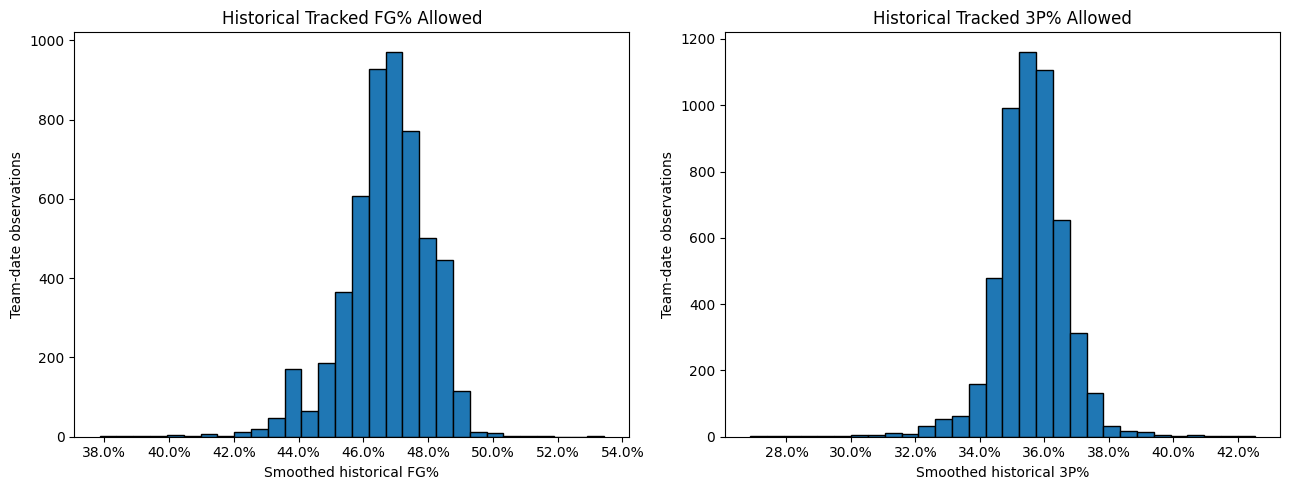

In [16]:
rate_summary = team_date[RATE_FEATURES].describe().T
rate_summary["median_percent"] = rate_summary["50%"] * 100
rate_summary["mean_percent"] = rate_summary["mean"] * 100
display(rate_summary.round(4))
rate_summary.reset_index(names="feature").to_csv(
    REPORT_DIR / "historical_defensive_rate_summary.csv", index=False
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(team_date[RATE_FEATURES[0]], bins=30, edgecolor="black")
axes[0].set(
    title="Historical Tracked FG% Allowed",
    xlabel="Smoothed historical FG%",
    ylabel="Team-date observations",
)
axes[0].xaxis.set_major_formatter(PercentFormatter(1))

axes[1].hist(team_date[RATE_FEATURES[1]], bins=30, edgecolor="black")
axes[1].set(
    title="Historical Tracked 3P% Allowed",
    xlabel="Smoothed historical 3P%",
    ylabel="Team-date observations",
)
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_historical_defensive_distributions.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

### Interpretation notes: defensive-rate distributions

After running the cell above, record 2–4 observations. Consider the range, median, mean, and spread of each feature. Avoid describing a higher tracked percentage allowed as proof that a team has worse overall defense; opponent quality and shot mix also affect these rates.

## 5. How much historical evidence supports each estimate?

The next section examines the prior tracked FG attempts, prior tracked 3P attempts, and prior games behind the defensive estimates. Rate estimates based on different amounts of history should not automatically be treated as equally precise.

,count,mean,std,min,25%,50%,75%,max
matchup_defense_prior_fg_attempts,5258.0,8531.51,4993.37,0.0,4211.75,8513.0,12776.25,19708.0
matchup_defense_prior_three_attempts,5258.0,3183.27,1859.61,0.0,1592.00,3175.0,4749.00,7619.0
matchup_defense_prior_games,5258.0,87.44,51.19,0.0,43.00,87.0,131.00,201.0


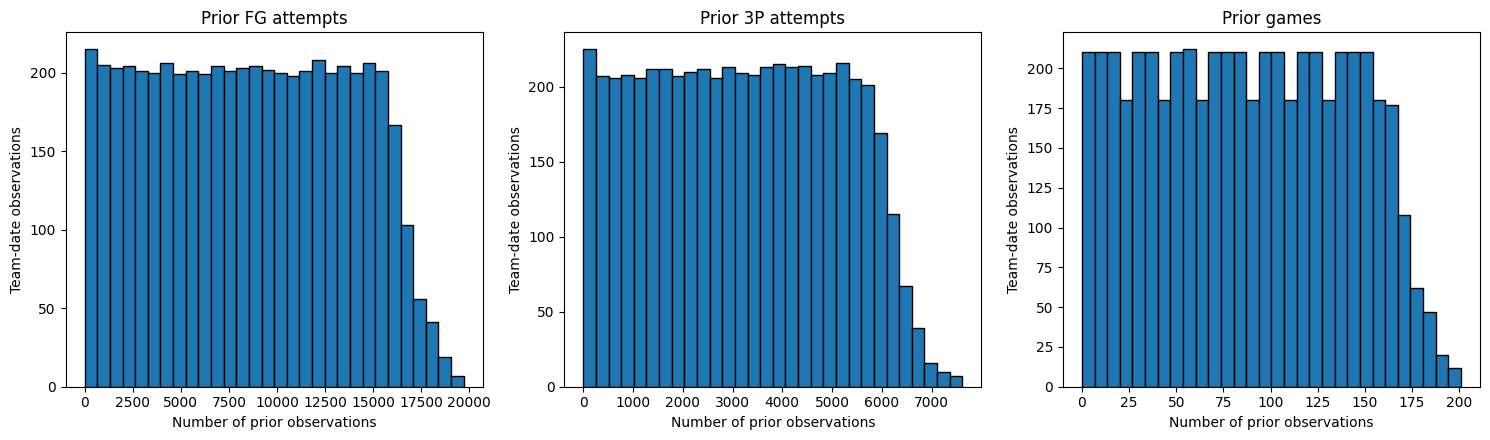

In [17]:
support_summary = team_date[SUPPORT_FEATURES].describe().T
display(support_summary.round(2))
support_summary.reset_index(names="feature").to_csv(
    REPORT_DIR / "historical_sample_size_summary.csv", index=False
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
support_plot_info = [
    (SUPPORT_FEATURES[0], "Prior FG attempts"),
    (SUPPORT_FEATURES[1], "Prior 3P attempts"),
    (SUPPORT_FEATURES[2], "Prior games"),
]
for ax, (column, title) in zip(axes, support_plot_info):
    ax.hist(team_date[column], bins=30, edgecolor="black")
    ax.set(title=title, xlabel="Number of prior observations", ylabel="Team-date observations")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_historical_sample_sizes.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

### Interpretation notes: historical support

Record whether most team-date estimates have substantial prior history or whether some dates have much smaller samples. Include the median and range for prior attempts and games. Explain why the amount of historical support matters when interpreting a percentage.

## 6. Compare teams using their latest historical estimates

For a simple cross-team comparison, we take each team's latest available historical feature row in the integrated shot dataset. These are not official league rankings. They are the latest estimates present in this particular dataset and should be interpreted alongside the support counts.

,team_label,opponent_team_id,game_date,matchup_defense_prior_fg_pct_smoothed,matchup_defense_prior_three_pct_smoothed,matchup_defense_prior_fg_attempts,matchup_defense_prior_three_attempts,matchup_defense_prior_games
27,OKC,1610612760,2026-05-30,0.4413,0.3502,19708.0,7619.0,201.0
19,BOS,1610612738,2026-05-02,0.4463,0.3437,17425.0,6618.0,181.0
25,DET,1610612765,2026-05-17,0.4530,0.3530,17427.0,6637.0,183.0
18,HOU,1610612745,2026-05-01,0.4581,0.3482,16820.0,5984.0,176.0
28,SAS,1610612759,2026-06-13,0.4593,0.3516,18488.0,6826.0,186.0
26,CLE,1610612739,2026-05-25,0.4603,0.3633,18776.0,6891.0,190.0
24,MIN,1610612750,2026-05-15,0.4626,0.3494,18136.0,6387.0,190.0
11,LAC,1610612746,2026-04-12,0.4644,0.3564,15941.0,6036.0,170.0
5,CHA,1610612766,2026-04-12,0.4655,0.3543,15855.0,6035.0,163.0
29,NYK,1610612752,2026-06-13,0.4665,0.3569,18837.0,7195.0,199.0


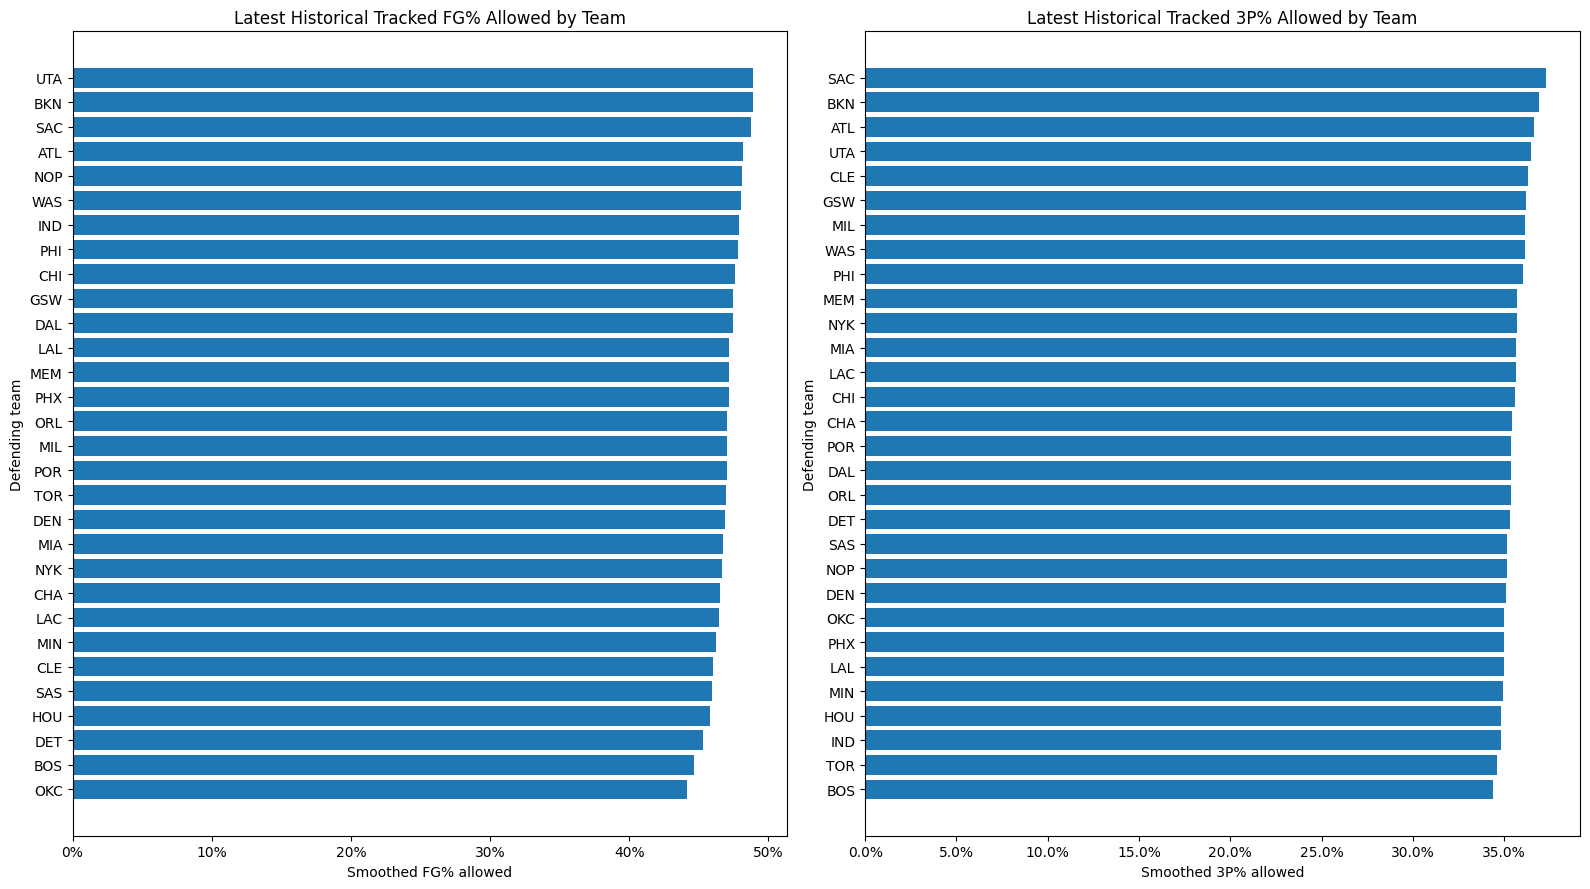

In [18]:
latest_team_history = (
    team_date.sort_values("game_date")
    .groupby("opponent_team_id", dropna=False)
    .tail(1)
    .copy()
)

# Add abbreviations from the shot data when available.
if "opponent_abbr" in shots.columns:
    abbreviation_map = (
        shots[["opponent_team_id", "opponent_abbr"]]
        .dropna()
        .drop_duplicates()
        .drop_duplicates("opponent_team_id")
    )
    latest_team_history = latest_team_history.merge(
        abbreviation_map,
        on="opponent_team_id",
        how="left",
        validate="one_to_one",
    )
    latest_team_history["team_label"] = latest_team_history["opponent_abbr"].fillna(
        latest_team_history["opponent_team_id"].astype(str)
    )
else:
    latest_team_history["team_label"] = latest_team_history["opponent_team_id"].astype(str)

latest_columns = [
    "team_label", "opponent_team_id", "game_date",
    *RATE_FEATURES, *SUPPORT_FEATURES,
]
latest_team_history = latest_team_history[latest_columns].sort_values(RATE_FEATURES[0])
display(latest_team_history.round(4))
latest_team_history.to_csv(REPORT_DIR / "latest_team_defensive_estimates.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 9))
fg_order = latest_team_history.sort_values(RATE_FEATURES[0])
axes[0].barh(fg_order["team_label"], fg_order[RATE_FEATURES[0]])
axes[0].set(
    title="Latest Historical Tracked FG% Allowed by Team",
    xlabel="Smoothed FG% allowed",
    ylabel="Defending team",
)
axes[0].xaxis.set_major_formatter(PercentFormatter(1))

three_order = latest_team_history.sort_values(RATE_FEATURES[1])
axes[1].barh(three_order["team_label"], three_order[RATE_FEATURES[1]])
axes[1].set(
    title="Latest Historical Tracked 3P% Allowed by Team",
    xlabel="Smoothed 3P% allowed",
    ylabel="Defending team",
)
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_latest_team_defensive_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

### Interpretation notes: team comparison

Identify a few relatively high and low teams, but describe them as having higher or lower **tracked percentages allowed** in this dataset. Check the attempt and game support columns before interpreting small differences. Do not call these adjusted defensive rankings.

## 7. Do historical matchup rates relate to subsequent shot outcomes?

This section connects each defending team-date historical estimate to the shots taken against that team on that date. We rank unique team-date estimates into quintiles, then summarize the observed outcomes of shots in each quintile. Quintile 1 represents lower historical tracked percentages allowed; quintile 5 represents higher historical tracked percentages allowed.

For the 3P analysis, we restrict the sample to three-point attempts. The relationship is descriptive and can be affected by shooter skill, location, shot difficulty, and shot selection. It is not a causal estimate or a model-performance test.

,quintile,attempts,makes,observed_fg_pct,mean_historical_defensive_pct
0,1,93104,42393,0.4553,0.4477
1,2,93149,43308,0.4649,0.4619
2,3,93060,43561,0.4681,0.4680
3,4,93937,44498,0.4737,0.4735
4,5,94287,45114,0.4785,0.4838


,quintile,attempts,makes,observed_fg_pct,mean_historical_defensive_pct
0,1,39436,14226,0.3607,0.3410
1,2,38882,13927,0.3582,0.3512
2,3,39054,13969,0.3577,0.3557
3,4,39004,14097,0.3614,0.3607
4,5,38799,13923,0.3588,0.3697


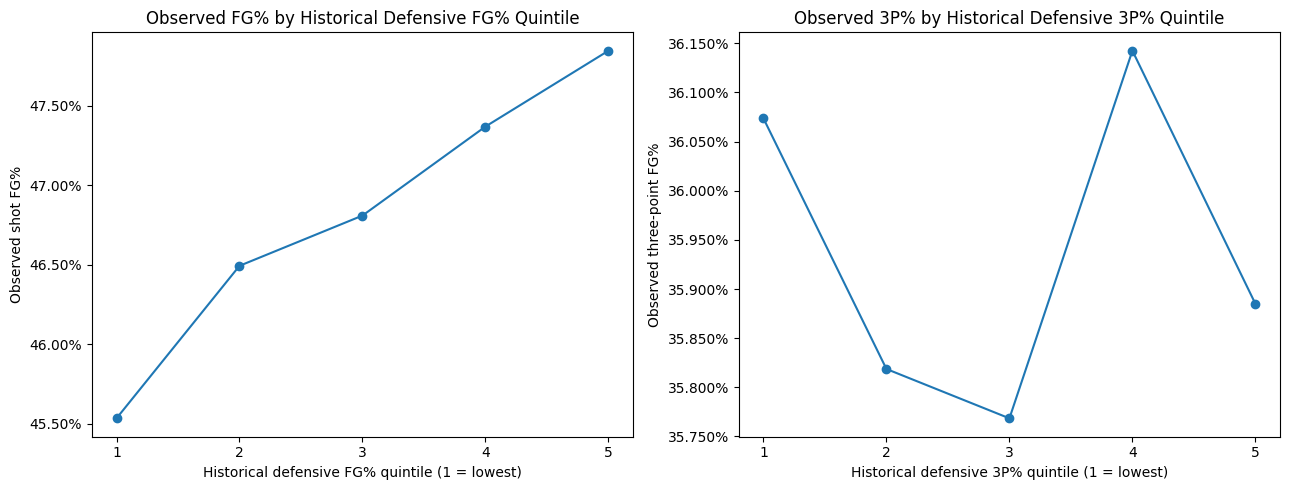

In [19]:
def identify_three_point_shots(frame: pd.DataFrame) -> pd.Series:
    """Return a Boolean mask identifying three-point field-goal attempts."""
    if "is_three_pointer" in frame.columns:
        return pd.to_numeric(frame["is_three_pointer"], errors="coerce").eq(1)
    if "shot_type" in frame.columns:
        return frame["shot_type"].astype("string").str.upper().eq("3PT FIELD GOAL")
    raise ValueError(
        "Cannot identify three-point attempts: neither is_three_pointer nor shot_type exists."
    )


def analyze_feature_quintiles(
    feature: str,
    output_name: str,
    three_point_only: bool = False,
    q: int = 5,
) -> pd.DataFrame | None:
    """Summarize later shot outcomes across quintiles of a historical team-date rate."""
    history = team_date[TEAM_DATE_KEYS + [feature]].dropna().drop_duplicates().copy()
    if history.duplicated(TEAM_DATE_KEYS).any():
        raise ValueError(f"More than one observation per defending team-date for {feature}.")
    if history[feature].nunique() < 2:
        print(f"Not enough variation to form quintiles for {feature}; skipping.")
        return None

    history["quintile"] = pd.qcut(history[feature], q=q, labels=False, duplicates="drop") + 1
    joined = shots.merge(
        history[TEAM_DATE_KEYS + ["quintile"]],
        on=TEAM_DATE_KEYS,
        how="inner",
        validate="many_to_one",
    )

    if three_point_only:
        joined = joined.loc[identify_three_point_shots(joined)].copy()

    joined["_target_numeric"] = pd.to_numeric(joined["shot_made_flag"], errors="coerce")
    joined = joined.loc[joined["_target_numeric"].notna()].copy()

    grouped = (
        joined.groupby("quintile", observed=True)
        .agg(
            attempts=("_target_numeric", "size"),
            makes=("_target_numeric", "sum"),
        )
        .reset_index()
    )
    grouped["observed_fg_pct"] = grouped["makes"] / grouped["attempts"]

    quintile_rate = (
        history.groupby("quintile", observed=True)[feature]
        .mean()
        .rename("mean_historical_defensive_pct")
        .reset_index()
    )
    result = grouped.merge(quintile_rate, on="quintile", how="left")
    result["quintile"] = result["quintile"].astype(int)

    display(result.round(4))
    result.to_csv(REPORT_DIR / f"{output_name}.csv", index=False)
    return result

fg_relationship = analyze_feature_quintiles(
    feature=RATE_FEATURES[0],
    output_name="shot_outcomes_by_historical_matchup_fg",
)

three_relationship = analyze_feature_quintiles(
    feature=RATE_FEATURES[1],
    output_name="three_point_outcomes_by_historical_matchup_3p",
    three_point_only=True,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
if fg_relationship is not None:
    axes[0].plot(
        fg_relationship["quintile"], fg_relationship["observed_fg_pct"], marker="o"
    )
    axes[0].set(
        title="Observed FG% by Historical Defensive FG% Quintile",
        xlabel="Historical defensive FG% quintile (1 = lowest)",
        ylabel="Observed shot FG%",
    )
    axes[0].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    axes[0].yaxis.set_major_formatter(PercentFormatter(1))
else:
    axes[0].set_visible(False)

if three_relationship is not None:
    axes[1].plot(
        three_relationship["quintile"],
        three_relationship["observed_fg_pct"],
        marker="o",
    )
    axes[1].set(
        title="Observed 3P% by Historical Defensive 3P% Quintile",
        xlabel="Historical defensive 3P% quintile (1 = lowest)",
        ylabel="Observed three-point FG%",
    )
    axes[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    axes[1].yaxis.set_major_formatter(PercentFormatter(1))
else:
    axes[1].set_visible(False)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "04_defensive_history_vs_shot_outcomes.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

### Interpretation notes: historical defense and subsequent outcomes

When interpreting the quintile tables and plots:

- Check the number of attempts in each quintile. Do not focus on a percentage without its denominator.
- Look for a broad pattern, but do not assume it must be perfectly monotonic.
- Remember that shooter quality, shot location, and shot mix vary across groups.
- The same historical team-date estimate is attached to multiple shots, so this is not an independent-sample significance test.

Write down whether observed shooting percentages broadly move in the direction suggested by the historical defensive rates. Treat this as a question to investigate in model testing, not proof of predictive improvement.

## 8. Relationship between the two new defensive-rate features

We examine whether teams with relatively high tracked FG% allowed also tend to have relatively high tracked 3P% allowed. Spearman correlation measures rank-based association; Pearson correlation measures linear association. Neither one tells us whether either feature improves shot prediction.

Spearman correlation:


,matchup_defense_prior_fg_pct_smoothed,matchup_defense_prior_three_pct_smoothed
matchup_defense_prior_fg_pct_smoothed,1.000000,0.491214
matchup_defense_prior_three_pct_smoothed,0.491214,1.000000


Pearson correlation:


,matchup_defense_prior_fg_pct_smoothed,matchup_defense_prior_three_pct_smoothed
matchup_defense_prior_fg_pct_smoothed,1.000000,0.531889
matchup_defense_prior_three_pct_smoothed,0.531889,1.000000


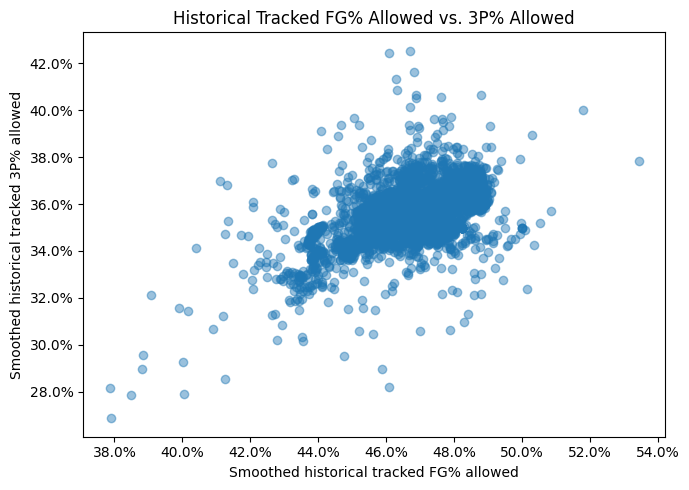

In [20]:
spearman_correlation = team_date[RATE_FEATURES].corr(method="spearman")
pearson_correlation = team_date[RATE_FEATURES].corr(method="pearson")

print("Spearman correlation:")
display(spearman_correlation)
print("Pearson correlation:")
display(pearson_correlation)

spearman_correlation.to_csv(REPORT_DIR / "matchup_feature_spearman_correlation.csv")
pearson_correlation.to_csv(REPORT_DIR / "matchup_feature_pearson_correlation.csv")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    team_date[RATE_FEATURES[0]],
    team_date[RATE_FEATURES[1]],
    alpha=0.45,
)
ax.set(
    title="Historical Tracked FG% Allowed vs. 3P% Allowed",
    xlabel="Smoothed historical tracked FG% allowed",
    ylabel="Smoothed historical tracked 3P% allowed",
)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "05_relationship_between_matchup_rate_features.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

## 9. Compare with Hayden's existing defensive features (optional)

Hayden's model-ready dataset may include historical opponent FG% allowed and opponent FG% allowed by shot zone. If that file and those columns are available, we join by shot identifiers and compare the features using Spearman correlations.

The measures differ in source and construction:

- Hayden's measures come from historical shot-chart outcomes.
- The new measures come from historical matchup-tracking statistics aggregated to the defending team.

Correlation can show whether the measures move together or capture different variation. A low correlation does not mean one is better; a high correlation does not prove the new features add no predictive value. Model comparisons are needed to test incremental value.

In [21]:
hayden_features = [
    "opponent_prior_fg_pct_smoothed",
    "opponent_zone_prior_fg_pct_smoothed",
]

if HAYDEN_MODEL_PATH.exists():
    hayden = pd.read_parquet(HAYDEN_MODEL_PATH)
    hayden.columns = hayden.columns.str.strip().str.lower()
    available_hayden_features = [
        column for column in hayden_features if column in hayden.columns
    ]
    join_keys = ["game_id", "game_event_id"]

    if not available_hayden_features:
        print("Optional comparison skipped: expected Hayden defensive columns were not found.")
    elif not set(join_keys).issubset(hayden.columns) or not set(join_keys).issubset(shots.columns):
        print("Optional comparison skipped: shot identifier columns are unavailable.")
    else:
        shots_for_join = normalize_shot_keys(shots)
        hayden_for_join = normalize_shot_keys(hayden)
        shots_for_join[RATE_FEATURES] = shots[RATE_FEATURES].to_numpy()
        hayden_for_join[available_hayden_features] = hayden[available_hayden_features].to_numpy()

        if hayden_for_join.duplicated(join_keys).any() or shots_for_join.duplicated(join_keys).any():
            print("Optional comparison skipped: duplicate shot identifiers were found.")
        else:
            comparison = shots_for_join[[*join_keys, *RATE_FEATURES]].merge(
                hayden_for_join[[*join_keys, *available_hayden_features]],
                on=join_keys,
                how="inner",
                validate="one_to_one",
            )
            compared_features = RATE_FEATURES + available_hayden_features
            correlation = comparison[compared_features].corr(method="spearman")
            print(f"Matched shot records: {len(comparison):,}")
            display(correlation)
            correlation.to_csv(
                REPORT_DIR / "hayden_vs_matchup_feature_spearman_correlations.csv"
            )
else:
    print(
        "Hayden's model-ready Parquet was not found at "
        f"{HAYDEN_MODEL_PATH}. Optional comparison skipped."
    )

Matched shot records: 467,537


,matchup_defense_prior_fg_pct_smoothed,matchup_defense_prior_three_pct_smoothed,opponent_prior_fg_pct_smoothed,opponent_zone_prior_fg_pct_smoothed
matchup_defense_prior_fg_pct_smoothed,1.000000,0.487570,0.970626,0.147642
matchup_defense_prior_three_pct_smoothed,0.487570,1.000000,0.513363,0.138043
opponent_prior_fg_pct_smoothed,0.970626,0.513363,1.000000,0.155142
opponent_zone_prior_fg_pct_smoothed,0.147642,0.138043,0.155142,1.000000


## 10. Key findings and limitations

Complete this section after running the notebook. Use the tables and charts above. Replace the bracketed prompts with actual values from your results; do not guess or copy expected patterns before seeing the output.

### Key findings


1. **Data integrity and feature coverage:** The integration preserved all 467,537 original shot records across 2,629 games. No duplicate shot identifiers, missing or additional shot records, changes to shot outcomes, or changes to opponent-team IDs were found. All six new matchup feature columns are populated. However, 464,848 shots (approximately 99.4%) have historical matchup information, while 2,689 shots (approximately 0.6%) do not. The `matchup_defense_has_history` feature identifies this difference.

2. **Feature distributions and historical support:** Historical tracked FG% allowed is concentrated around 46–48%, while historical tracked 3P% allowed is concentrated around 35–37%. The median estimates are approximately 46.78% and 35.57%, respectively. The median observation has 8,513 prior FG attempts, 3,175 prior three-point attempts, and 87 prior games supporting its estimates. However, some observations have little or no previous history, so the amount of information behind each estimate is not always the same.

3. **Differences between teams:** The latest historical estimates show some variation across the 30 defending teams. However, the differences are relatively modest. These percentages describe the results in the available matchup-tracking data and should not be treated as a final ranking of the NBA's best and worst defensive teams.

4. **Relationship with shot outcomes:** The FG% analysis shows a clear pattern. As historical defensive FG% increases across the five groups, observed shot FG% also increases, from 45.53% in the lowest group to 47.85% in the highest group. The three-point analysis shows a less consistent pattern, with observed 3P% staying between approximately 35.77% and 36.14%. This suggests that historical defensive FG% has a clearer relationship with subsequent shot outcomes than historical defensive 3P% in this analysis. These results describe an association and do not establish that the features improve prediction.

5. **Relationship with other defensive features:** The new historical FG% and 3P% features have a moderate positive relationship, with a Spearman correlation of approximately 0.49. In the comparison with Hayden's features, the new historical matchup FG% feature has a very strong relationship with Hayden's `opponent_prior_fg_pct_smoothed` feature (approximately 0.97). This suggests that the two features may contain very similar information. The new features still need to be tested in a model to determine whether they provide additional value.



### Limitations

- Matchup-tracking data is aggregated to the defending team and game; it does not identify the defender assigned to each shot.
- Tracked matchup statistics may not reconcile exactly with official shot-chart makes and attempts.
- Opponent shooting percentages are affected by offensive player quality and shot selection, not defense alone.
- The smoothing prior is a design choice and has not yet been tuned through validation.
- Descriptive associations do not demonstrate incremental predictive performance.

### Implications for model testing

The next stage should compare feature sets using the same chronological data splits and evaluation metrics. At minimum, compare a baseline feature set without these matchup-derived features against the same feature set with them added. Keep model selection separate from the final test set.

**Do not claim that the matchup features improve prediction until this comparison has been completed.**

In [23]:
# Save a compact manifest so the analysis outputs can be traced later.
manifest = {
    "shot_dataset": str(INTEGRATED_PATH),
    "original_shot_dataset": str(ORIGINAL_PATH),
    "matchup_summary": str(MATCHUP_SUMMARY_PATH),
    "shot_rows": int(len(shots)),
    "team_date_observations": int(len(team_date)),
    "defending_teams": int(shots["opponent_team_id"].nunique()),
    "matchup_features": MATCHUP_FEATURES,
    "missing_matchup_feature_rows": int(shots[MATCHUP_FEATURES].isna().any(axis=1).sum()),
}

manifest_path = REPORT_DIR / "matchup_eda_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")

print("Supplementary matchup EDA notebook completed.")
print("Tables and manifest:", REPORT_DIR)
print("Figures:", FIGURE_DIR)
print("Manifest:", manifest_path)
print(
    "\nReminder: these analyses describe distributions and associations. They do not "
    "establish that matchup features improve out-of-sample prediction. That requires "
    "controlled model comparisons using the same chronological splits and evaluation metrics."
)

Supplementary matchup EDA notebook completed.
Tables and manifest: C:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\reports\matchup_eda
Figures: C:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\figures\matchup_eda
Manifest: C:\Users\shaur\OneDrive\Documents\Desktop\EclipseBasketballFall26\reports\matchup_eda\matchup_eda_manifest.json

Reminder: these analyses describe distributions and associations. They do not establish that matchup features improve out-of-sample prediction. That requires controlled model comparisons using the same chronological splits and evaluation metrics.
